<img src="images/trump-reporters.jpg" width=700>

> *President Trump said in a social media post that he is offering a $1 million reward for anyone who reports voter fraud — in past elections or in the upcoming midterm elections — that leads to a conviction.*

# 01 - First look: NYS Voting

Researchers at Stanford and Columbia have prepared for us a snapshot of the New York State voter file. The state [makes it available to anyone who requests it](https://elections.ny.gov/freedom-information-law-foil-requests) via FOIL. 

The raw data includes all 62 New York counties, including New York City. The source file is a "snapshot" from December 27, 2022. As a table, it contains 20,919,063 rows, 114 columns and 19,937,571 distinct `state_vid` values. 

The term "snapshot" here means that on December 27th of 2022, a copy of the voter file was compiled. It records people at their then-current addresses with then-current information. If after that date they move or change parties or leave the state, their data will change. So the information for December 2023 might look different for a person than it did in 2022.

IDs are never null or blank. The same ID can occur under multiple registration statuses. (Why?) The file has 981,492 more rows than distinct IDs, so a row is not necessarily a distinct voter.

We have included a "skill" for our claude agent that adapts its behavior when you ask a question about some data. Every question goes through six steps: **Question → Plan → Compute → Check → Claim → Review**. You can tell the agent to ignore this if it's too heavy-handed. (Write "just", "quick", "only", "skip the steps", or simply ask for a plot or a table without asking a question.)

## The data

We have created a random sample of 100,000 voters from this file. That's not 100,000 rows, but voters. The distinction is that some voters have multiple lines. For the most part, they are `PURGE`/`ACTIVE` pairs, with someone moving from one part of the state to another (the old registration remaining on the roles purged, and the new registration is acitive at their new location).

Let's load the data!

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

voters = pd.read_csv("data/NY_2022_12_class_100k.csv")
type(voters)

pandas.DataFrame

In [2]:
# What are the dimensions of the table?
voters.shape

(104906, 105)

In [ ]:
# Can we see the first few rows of the table?

voters.head()

,file_id,snapshot_id,snapshot_sub_id,state,reg_date,updated_date,last_contact_date,status,sex,race,...,voted_20191105,voted_20200428,voted_20200623,voted_20201103,voted_20210622,voted_20211102,voted_20220628,voted_20220823,voted_20221108,state_vid
0,NY-2343,40,NaN,NY,1997-01-16,NaN,NaN,ACTIVE,MALE,NOT REPORTED,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,JCIPLJAMEJJDJAKBGFGACDJPFJPJCMGP
1,NY-2343,40,NaN,NY,1997-02-03,NaN,NaN,ACTIVE,MALE,NOT REPORTED,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,JEAMBBGMAFOFLFAHNJNJGAEGCFPFPBAA
2,NY-2343,40,NaN,NY,2005-10-04,NaN,NaN,PURGED,MALE,NOT REPORTED,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,OMLKHLCJOFMKDCILKBIAILGDNIKGOELG
3,NY-2343,40,NaN,NY,1997-02-03,NaN,NaN,ACTIVE,MALE,NOT REPORTED,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,MFHLAHAIOMDGDOIGJBHODKNMCHGPHJLM
4,NY-2343,40,NaN,NY,1960-10-15,NaN,NaN,ACTIVE,FEMALE,NOT REPORTED,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,FMGMIFIEJFACFBOMFBKMKONOBJGJGAGH


In [2]:
# first set an option so you show all the columns of a data frame
pd.set_option("display.max_columns", None)

# then try again
voters.head()

,file_id,snapshot_id,snapshot_sub_id,state,reg_date,updated_date,last_contact_date,status,sex,race,party,birth_year,age,voterfile_county,reg_address_zip,reg_address_city,mail_address_zip,mail_address_city,mail_address_state,unstandardized_party,unstandardized_sex,unstandardized_race,geocoded,geocoded_score,geocoded_type,geocoded_county,geocoded_puma_2000,geocoded_puma_2010,geocoded_puma_2020,county,voted_19921103,voted_19930914,voted_19931102,voted_19940913,voted_19941108,voted_19950912,voted_19951107,voted_19960307,voted_19960910,voted_19961105,voted_19970909,voted_19971104,voted_19980915,voted_19981103,voted_19990914,voted_19991102,voted_20000307,voted_20000912,voted_20001107,voted_20010911,voted_20011106,voted_20020910,voted_20021105,voted_20030909,voted_20031104,voted_20040302,voted_20040914,voted_20041102,voted_20050913,voted_20051108,voted_20060912,voted_20061107,voted_20070918,voted_20071106,voted_20080205,voted_20080909,voted_20081104,voted_20090908,voted_20091103,voted_20100914,voted_20101102,voted_20110913,voted_20111108,voted_20120424,voted_20120626,voted_20120913,voted_20121106,voted_20130910,voted_20131105,voted_20140624,voted_20140909,voted_20141104,voted_20150910,voted_20151103,voted_20160419,voted_20160628,voted_20160913,voted_20161108,voted_20170912,voted_20171107,voted_20180424,voted_20180626,voted_20180913,voted_20181106,voted_20190625,voted_20191105,voted_20200428,voted_20200623,voted_20201103,voted_20210622,voted_20211102,voted_20220628,voted_20220823,voted_20221108,state_vid
0,NY-2343,40,NaN,NY,1997-01-16,NaN,NaN,ACTIVE,MALE,NOT REPORTED,DEM,1967,55.0,SUFFOLK,11702,BABYLON,NaN,BABYLON,NY,DEM,M,NaN,1,100.0,POINTADDRESS,SUFFOLK,4311.0,3312.0,3312.0,SUFFOLK,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,JCIPLJAMEJJDJAKBGFGACDJPFJPJCMGP
1,NY-2343,40,NaN,NY,1997-02-03,NaN,NaN,ACTIVE,MALE,NOT REPORTED,OTHER,1939,83.0,SUFFOLK,11961,RIDGE,NaN,BROOKHAVEN,NY,CON,M,NaN,1,100.0,POINTADDRESS,SUFFOLK,4303.0,3304.0,3304.0,SUFFOLK,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,JEAMBBGMAFOFLFAHNJNJGAEGCFPFPBAA
2,NY-2343,40,NaN,NY,2005-10-04,NaN,NaN,PURGED,MALE,NOT REPORTED,DEM,1935,87.0,SUFFOLK,11787,SMITHTOWN,NaN,SMITHTOWN,NY,DEM,M,NaN,1,100.0,POINTADDRESS,SUFFOLK,4302.0,3303.0,3303.0,SUFFOLK,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,OMLKHLCJOFMKDCILKBIAILGDNIKGOELG
3,NY-2343,40,NaN,NY,1997-02-03,NaN,NaN,ACTIVE,MALE,NOT REPORTED,OTHER,1962,60.0,SUFFOLK,11940,E MORICHES,NaN,BROOKHAVEN,NY,OTH,M,NaN,1,100.0,POINTADDRESS,SUFFOLK,4305.0,3306.0,3306.0,SUFFOLK,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,MFHLAHAIOMDGDOIGJBHODKNMCHGPHJLM
4,NY-2343,40,NaN,NY,1960-10-15,NaN,NaN,ACTIVE,FEMALE,NOT REPORTED,REP,1932,90.0,SUFFOLK,11746,DIX HILLS,NaN,HUNTINGTON,NY,REP,F,NaN,1,100.0,POINTADDRESS,SUFFOLK,4301.0,3302.0,3302.0,SUFFOLK,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0

Now let's look at the `status` values. How many people are labled with each category? 

In [5]:
voters["status"].value_counts()

status
ACTIVE        61126
PURGED        38527
INACTIVE       4864
INELIGIBLE      389
Name: count, dtype: int64

Do the same thing, but with the variable describing if someone voted in the midterm election on November 8, 2022.

In [3]:
voters["voted_20221108"].value_counts()

voted_20221108
0.0    64351
1.0    23074
Name: count, dtype: int64

In [4]:
voters[["voted_20221108","status"]].value_counts()

voted_20221108  status  
0.0             ACTIVE      40514
1.0             ACTIVE      20612
0.0             PURGED      18988
                INACTIVE     4849
1.0             PURGED       2447
                INACTIVE       15
Name: count, dtype: int64

## Jumping far ahead

We can take that category counting idea and look at another variable. The `reg_date` is good, although maybe too granular. Let's strip off the month and day and look at just the years...

In [6]:
voters["reg_date"].str.split("-").str[0].head()

0    1997
1    1997
2    2005
3    1997
4    1960
Name: reg_date, dtype: object

We can now tally the categories. See that 2016 was a good year for registrations! This list is nice but what are we irresistably drawn to do next?

In [7]:
voters["reg_date"].str.split("-").str[0].value_counts()

reg_date
2016    5830
2020    5516
2008    5325
2004    5077
2012    4318
        ... 
1925       1
1944       1
1952       1
1932       1
1934       1
Name: count, Length: 76, dtype: int64

That's right, a graph! We can ask our claude agent to write the code for us, putting the cell just below this one. 

A bar chart of how many voters registered in each year, in order from the earliest year to the latest.

> *Below the cell that's highlighted, create a barplot (using Altair) of the counts of people registering each year, in numerical order by year.*

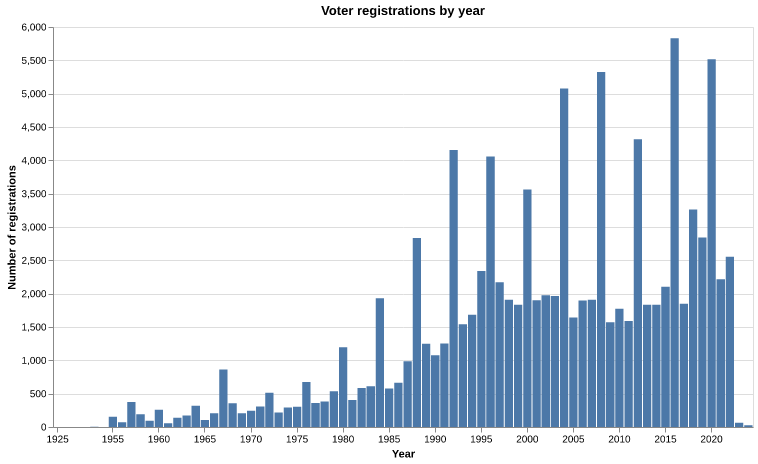

In [8]:
import altair as alt

alt.renderers.enable("png")  # draw as an image so it shows in VS Code

registrations = (
    voters["reg_date"].str.split("-").str[0].astype(int)
    .value_counts().sort_index()
    .rename_axis("year").reset_index(name="count")
)

alt.Chart(registrations).mark_bar().encode(
    x=alt.X("year:O", title="Year", sort="ascending", axis=alt.Axis(values=list(range(1925, 2030, 5)), labelAngle=0)),
    y=alt.Y("count:Q", title="Number of registrations"),
).properties(title="Voter registrations by year", width=700, height=400)

What does this plot tell you? Can we break it down a little more?

> *Make the equivalent of a "pyramid plot" where we focus on just republican vs democratic registrations and we limit the data to 1996-2022.*

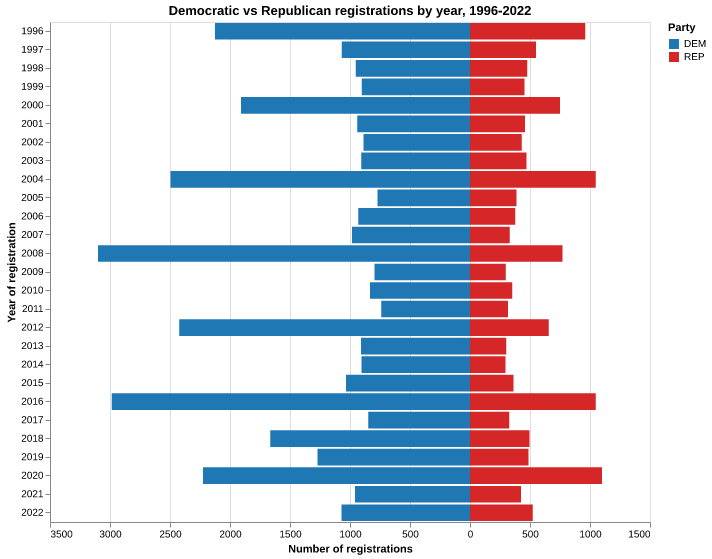

In [9]:
import altair as alt

alt.renderers.enable("png")  # draw as an image so it shows in VS Code

voters["year"] = voters["reg_date"].str.split("-").str[0].astype(int)

pyramid = (
    voters[voters["party"].isin(["DEM", "REP"]) & voters["year"].between(1996, 2022)]
    .groupby(["year", "party"]).size().reset_index(name="count")
)
# Democrats are drawn to the left of zero, Republicans to the right
pyramid["signed_count"] = pyramid["count"].where(pyramid["party"] == "REP", -pyramid["count"])

alt.Chart(pyramid).mark_bar().encode(
    y=alt.Y("year:O", title="Year of registration", sort="ascending"),
    x=alt.X("signed_count:Q", title="Number of registrations", axis=alt.Axis(labelExpr="abs(datum.value)")),
    color=alt.Color("party:N", title="Party", scale=alt.Scale(domain=["DEM", "REP"], range=["#1f77b4", "#d62728"])),
).properties(title="Democratic vs Republican registrations by year, 1996-2022", width=600, height=500)

---
## Questions from the researchers

While this is a warm up data set, there's a great deal of information to be drawn about the previous midterm election. The researchers had these questions...

> There’s so much to do with the dataset. A few ideas that come to mind:
> 
> * Compare party registration across generations. Are older voters really more conservative than younger voters?
> 
> * Look at recent registrations. Are Dems or Reps gaining ground?
> 
> * Study who are the most politically active voters. Certainly older folks, but it might also vary with political geography. (Cool GIS task here). 
> 
> * How does party registration correlate with regional demographics, economics etc?

When we're done, we can ask our friend to write the chat as a markdown file and store it in our folder. That way we have a complete transcript of what we did.

> *Can you write a markdown version of this chat in the lesson_1 folder?*

---
## APIs

<img src="images/ts.png" width=700>

We are going to continue our work on APIs (Application Programming Interfaces) by looking at one of a number of services that provide access to social media posts. Here we are using [Social Fetch](https://www.socialfetch.dev/). See the course notes for a description of the service.

The file at `data/ts.json` (see your **Explorer** panel on the left) is the saved result of an API call to Truth Social for President Trump's account. We pulled the 20 most recent posts as of 5am November 4th. Knowing what we know about dictioinaries and lists, tell me where you would find the sequence of posts. Then, let's load it with Python's `json` module and look at the top-level keys first.

In [10]:
import json
import pandas as pd

# first we open() the file
f = open("data/ts.json")

# then we load() the contents of the file into Python objects
api_result = json.load(f)

# The top level has "data" and "meta". The posts are inside "data".
print(api_result.keys())
print(api_result["data"].keys())
print(len(api_result["data"]["posts"]))

dict_keys(['data', 'meta'])
dict_keys(['lookupStatus', 'profile', 'posts', 'page'])
20


The list under `posts` has 20 entries, one dictionary per post. `pd.json_normalize` turns a list of dictionaries into a table, flattening nested pieces like `metrics` into columns such as `metrics.replies`. We also convert `createdAt` from text into a real date/time.

In [11]:
# read the posts in as a pandas data frame
posts = pd.json_normalize(api_result["data"]["posts"])
print(type(posts))

# have a look
print(posts.shape)
posts.columns

# have a look... at the dimensions of the table and then the column names
print(posts.shape)
posts.columns

<class 'pandas.DataFrame'>
(20, 33)
(20, 33)


Index(['id', 'url', 'createdAt', 'editedAt', 'text', 'spoilerText', 'language',
       'visibility', 'isSensitive', 'inReplyToStatusId', 'inReplyToAccountId',
       'quoteId', 'repostOfId', 'media', 'linkPreview', 'poll', 'quote',
       'author.platform', 'author.id', 'author.handle', 'author.displayName',
       'author.avatarUrl', 'author.isVerified', 'author.profileUrl',
       'metrics.replies', 'metrics.reposts', 'metrics.favorites',
       'metrics.upvotes', 'metrics.downvotes', 'quote.id', 'quote.url',
       'quote.text', 'quote.authorHandle'],
      dtype='str')

So 33 columns and 20 rows. Each row is a post. Below we look at just a few columns...

In [12]:
# print out 20 posts but focus on the time, the text and some metrics

posts[["createdAt", "text", "metrics.replies", "metrics.reposts", "metrics.favorites"]]

,createdAt,text,metrics.replies,metrics.reposts,metrics.favorites
0,2026-11-04T04:52:32.242Z,"Why does FoxNews have Bill de Blasio, the Wors...",6997,3620,17091
1,2026-11-04T04:40:22.509Z,NaN,5710,5021,21160
2,2026-11-04T04:38:14.224Z,"I’m going to become a Political Pundit, both g...",3967,3278,16345
3,2026-11-04T04:35:27.759Z,"If Greg Abbott, the Governor of Texas, hadn’t ...",2744,3161,15006
4,2026-11-04T03:37:43.436Z,"I wasn’t on the Ballot and if I was, we would ...",13683,3880,19230
5,2026-11-04T00:00:40.825Z,FoxNews Ratings are way down (27%!) because th...,8371,5434,22259
6,2026-11-03T23:51:32.297Z,NaN,1417,3055,13584
7,2026-11-03T23:51:08.724Z,NaN,668,2227,10438
8,2026-11-03T23:36:04.318Z,"The FoxNews Poll, always the worst, is so insu...",2279,3998,17897
9,2026-11-03T23:04:10.758Z,KENTUCKY CLOSING SOON. A BIG DEAL! President DJT,865,2750,14413


### Question

How many of the 20 posts in `posts` have more than 1,000 replies? We use the column `metrics.replies`, and "over 1000" means strictly greater than 1000 (a post with exactly 1000 would not count).

### Plan

We make a True/False value for each post (is `metrics.replies` greater than 1000?) and count the Trues. Assumptions: every one of the 20 rows counts as a post, including any that have no text or look like reposts; and there are no missing values in `metrics.replies` (the Check will confirm this).

### Compute

This compares each post's reply count to 1000, which gives True or False, and then adds up the Trues.

In [13]:
over_1000 = posts["metrics.replies"] > 1000
over_1000.sum()

np.int64(13)

### Check

Here we count a second way, without the data frame: loop over the raw posts in `api_result` and count by hand. We also confirm that "over" and "1000 or fewer" add up to all 20 posts, that no reply counts are missing, and we list the reply counts of the posts nearest the 1000 line.

In [14]:
# Count by hand from the raw JSON
count = 0
for post in api_result["data"]["posts"]:
    if post["metrics"]["replies"] > 1000:
        count += 1
print("Counted by hand:", count)

# Do the parts add up to the whole?
print("1000 or fewer:", (posts["metrics.replies"] <= 1000).sum())
print("Missing reply counts:", posts["metrics.replies"].isna().sum())
print("Total posts:", len(posts))

# The reply counts, largest to smallest, so we can see which side of 1000 each falls on
posts["metrics.replies"].sort_values(ascending=False).tolist()

Counted by hand: 13
1000 or fewer: 7
Missing reply counts: 0
Total posts: 20


[13683,
 8371,
 6997,
 5710,
 3967,
 3585,
 2744,
 2279,
 1417,
 1362,
 1204,
 1077,
 1049,
 946,
 865,
 672,
 668,
 569,
 357,
 0]

**Claim:** *(Your turn: one sentence on what you conclude, with the numbers that support it.)*

### Question

Among voters whose `status` is `ACTIVE` or `INACTIVE`, what percentage voted in the November 8, 2022 election, for each `party`? "Voted" means `voted_20221108` equals 1. (There is no column where `status` equals 1: `status` holds words like `ACTIVE`, and voting is recorded in the `voted_` columns.)

### Plan

First keep only the rows with status `ACTIVE` or `INACTIVE`. Then, within each party, take the average of `voted_20221108`: because it is 1 for voted and 0 for didn't, the average is the fraction who voted, and multiplying by 100 gives a percentage. Assumption (you chose this): voters with a blank `voted_20221108` (registered after the election) are left out, which pandas does automatically when averaging.

### Compute

This keeps the `ACTIVE` and `INACTIVE` voters, then reports for each party the number of voters with a known value, the number who voted, and the percentage who voted.

In [8]:
current = voters[voters["status"].isin(["ACTIVE", "INACTIVE"])]

turnout = current.groupby("party")["voted_20221108"].agg(["count", "sum", "mean"])
turnout.columns = ["voters_with_known_value", "voted", "pct_voted"]
turnout["pct_voted"] = turnout["pct_voted"] * 100
turnout.round(1)

,voters_with_known_value,voted,pct_voted
party,,,
DEM,32666,7855.0,24.0
NONPARTISAN,15318,4010.0,26.2
OTHER,3305,1275.0,38.6
REP,14701,7487.0,50.9


### Check

This checks the answer three other ways: (1) a cross-tabulation of party against voted/didn't vote, which computes the percentages from the raw counts; (2) the parts adding up to the whole, including blanks and the number of rows we kept; and (3) whether any `state_vid` appears more than once among the rows we kept, since a repeated voter would be counted twice.

In [9]:
# (1) A different route: cross-tabulate party by voted, percentages computed within each party
print(pd.crosstab(current["party"], current["voted_20221108"], normalize="index").mul(100).round(1))

# (2) Do the parts add up to the whole?
print()
print("Rows kept (ACTIVE or INACTIVE):", len(current))
print("  with a 0 or 1:", current["voted_20221108"].notna().sum())
print("  blank:", current["voted_20221108"].isna().sum())
print("Rows ACTIVE + INACTIVE in the full table:", voters["status"].isin(["ACTIVE", "INACTIVE"]).sum())

# (3) Does any voter ID appear more than once among the kept rows?
print()
print("Repeated state_vid among kept rows:", current["state_vid"].duplicated().sum())

# Where do the blanks come from? Blanks by status and by registration year
print()
print(current[current["voted_20221108"].isna()]["status"].value_counts())
print(current[current["voted_20221108"].isna()]["reg_date"].str[:4].value_counts().head(5))

voted_20221108   0.0   1.0
party                     
DEM             76.0  24.0
NONPARTISAN     73.8  26.2
OTHER           61.4  38.6
REP             49.1  50.9

Rows kept (ACTIVE or INACTIVE): 65990
  with a 0 or 1: 65990
  blank: 0
Rows ACTIVE + INACTIVE in the full table: 65990

Repeated state_vid among kept rows: 0

Series([], Name: count, dtype: int64)
Series([], Name: count, dtype: int64)


**Claim:** *(Your turn: one sentence on what you conclude, with the numbers that support it.)*